# Startup Success and Funding Analysis Using Data Science Techniques

# Problem Statement

Startups operate in highly uncertain and competitive environments, where factors such as funding received, number of funding rounds, industry category, and other startup characteristics may be associated with their outcomes. Understanding these factors can help identify patterns that distinguish successful startups from unsuccessful ones.

This project aims to analyze startup data using data science and statistical techniques to explore funding patterns, study relationships among important startup characteristics, and investigate the factors associated with startup success or failure. The analysis will use data preprocessing, exploratory data analysis, statistical methods, data visualization, and suitable regression techniques to derive meaningful and evidence-based insights from the dataset.

# Project Objectives

The main objectives of this project are:

1. To understand the structure, attributes, and characteristics of the startup dataset.

2. To preprocess and clean the dataset by identifying and handling missing values, duplicate records, inconsistent values, incorrect data types, and outliers wherever applicable.

3. To perform exploratory data analysis and descriptive statistical analysis to understand startup funding patterns and other important characteristics.

4. To compare successful and failed startups based on relevant funding and startup-related features.

5. To examine relationships between important numerical variables, such as the number of funding rounds and total funding received.

6. To apply appropriate statistical techniques and hypothesis testing to determine whether observed differences and relationships are statistically significant.

7. To apply suitable regression techniques to study relationships between variables and model startup outcomes where appropriate.

8. To create meaningful data visualizations that clearly represent important patterns, relationships, and results.

9. To derive evidence-based findings regarding the factors associated with startup success and failure.

# Scope of the Project

This project focuses on analyzing the provided startup dataset to study funding patterns and factors associated with startup success and failure. The analysis considers available attributes such as total funding, number of funding rounds, startup category, location, funding dates, and startup status/outcome.

The project covers data understanding, data preprocessing and cleaning, exploratory data analysis, descriptive statistics, statistical testing, data visualization, and suitable regression techniques. The analysis is limited to the information available in the dataset and does not consider external factors that are not represented in the data.

# Dataset Description

The dataset used in this project contains information about startups and includes various attributes related to their industry, location, funding history, current status, and outcome. These attributes are used to analyze funding patterns and investigate differences between successful and failed startups.

### Dataset Source

The dataset used in this project is derived from the **“Big Startup Success/Fail Dataset from Crunchbase”**, available on Kaggle and uploaded by **yanmaksi**. The original dataset contains **66,368 company records** derived from Crunchbase and includes information related to startup characteristics, funding, location, and company status.

For this project, the original dataset was filtered to include Indian companies. Companies with an operating status were excluded because their final success or failure outcome was not yet resolved. The remaining companies were classified based on their status:

- **Closed → Failure**
- **Acquired → Success**
- **IPO → Success**

After filtering and preparation, the dataset used for this project contains **129 Indian startups with resolved outcomes**.

### Dataset Structure

The final dataset used for analysis contains **129 startup records and 14 attributes**. Each row represents an individual startup, while the columns represent different characteristics related to the startup, including its category, location, funding information, dates, status, and final outcome.

The dataset contains a combination of **numerical, categorical, and date-related attributes**, making it suitable for exploratory data analysis, statistical analysis, visualization, and regression-based techniques.

In [29]:
import pandas as pd

In [30]:
df = pd.read_excel("/content/indian_startup_success_failure_dataset.xlsx")

In [31]:
df.head()

,Name,Category_list,Funding_total_usd,Funding_rounds,State_code,Region,City,Founded_at,First_funding_at,Last_funding_at,Status,Outcome,Homepage_url,Permalink
0,1CLICK,Chat|Mobile,-,1,19.0,Bangalore,Bangalore,2012-11-01,2014-01-26,2014-01-26,acquired,Success,http://1click.io,/organization/1click
1,ABC Live,Advertising,25000,1,5.0,Chandigarh,Chandigarh,2007-12-05,2007-01-05,2007-01-05,closed,Failure,http://abclive.in,/organization/abc-live
2,Acision,Mobile,100000000,1,10.0,New Delhi,Gurgaon,1992-01-01,2010-10-05,2010-10-05,acquired,Success,http://www.acision.com,/organization/acision
3,Adhysteria,Classifieds|Curated Web|Video,10000,1,16.0,Mumbai,Mumbai,2007-09-01,2007-07-01,2007-07-01,closed,Failure,http://www.adhysteria.com,/organization/adhysteria
4,Alsbridge,BPO Services|Consulting|Outsourcing,-,1,10.0,New Delhi,Gurgaon,2003-01-01,2013-01-08,2013-01-08,closed,Failure,http://www.alsbridge.com,/organization/alsbridge


## Dataset Structure

The number of rows and columns is checked to understand the size of the dataset. The column names are also displayed to identify the attributes available for analysis.

In [32]:
df.shape

(129, 14)

In [33]:
df.columns

Index(['Name', 'Category_list', 'Funding_total_usd', 'Funding_rounds',
       'State_code', 'Region', 'City', 'Founded_at', 'First_funding_at',
       'Last_funding_at', 'Status', 'Outcome', 'Homepage_url', 'Permalink'],
      dtype='object')

## Data Types

The data types of the columns are checked to understand how each attribute is stored in the dataset.

In [34]:
df.dtypes

,0
Name,object
Category_list,object
Funding_total_usd,object
Funding_rounds,int64
State_code,float64
Region,object
City,object
Founded_at,object
First_funding_at,object
Last_funding_at,object


In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               129 non-null    object 
 1   Category_list      123 non-null    object 
 2   Funding_total_usd  129 non-null    object 
 3   Funding_rounds     129 non-null    int64  
 4   State_code         126 non-null    float64
 5   Region             125 non-null    object 
 6   City               125 non-null    object 
 7   Founded_at         105 non-null    object 
 8   First_funding_at   129 non-null    object 
 9   Last_funding_at    129 non-null    object 
 10  Status             129 non-null    object 
 11  Outcome            129 non-null    object 
 12  Homepage_url       126 non-null    object 
 13  Permalink          129 non-null    object 
dtypes: float64(1), int64(1), object(12)
memory usage: 14.2+ KB


### Description of Dataset Attributes

> Add blockquote



The dataset contains 14 attributes describing different characteristics of each startup:

| Attribute | Description | Type |
|---|---|---|
| **Name** | Name of the startup/company. | Categorical |
| **Category_list** | Industry or business category in which the startup operates. | Categorical |
| **Funding_total_usd** | Total amount of funding received by the startup in US dollars. | Numerical |
| **Funding_rounds** | Total number of funding rounds completed by the startup. | Numerical |
| **State_code** | State code representing the location of the startup. | Categorical |
| **Region** | Geographic region associated with the startup. | Categorical |
| **City** | City in which the startup is located. | Categorical |
| **Founded_at** | Date on which the startup was founded. | Date |
| **First_funding_at** | Date on which the startup received its first recorded funding. | Date |
| **Last_funding_at** | Date of the startup's most recent recorded funding. | Date |
| **Status** | Final company status, such as closed, acquired, or IPO. | Categorical |
| **Outcome** | Final outcome of the startup, classified as Success or Failure. | Categorical |
| **Homepage_url** | Website/homepage associated with the startup. | Categorical |
| **Permalink** | Unique reference/link associated with the startup record. | Categorical |

## Initial Statistical Summary

Basic descriptive statistics are displayed to get an initial understanding of the numerical attributes.

In [36]:
df.describe()

,Funding_rounds,State_code
count,129.000000,126.000000
mean,1.356589,15.873016
std,0.908282,7.085742
min,1.000000,2.000000
25%,1.000000,10.000000
50%,1.000000,16.000000
75%,1.000000,19.000000
max,9.000000,36.000000


In [37]:
df.describe(include='object')

,Name,Category_list,Funding_total_usd,Region,City,Founded_at,First_funding_at,Last_funding_at,Status,Outcome,Homepage_url,Permalink
count,129,123,129,125,125,105,129,129,129,129,126,129
unique,129,91,74,18,23,72,120,122,3,2,126,129
top,1CLICK,Software,-,Bangalore,Bangalore,2012-01-01,2007-01-01,2007-01-01,closed,Failure,http://1click.io,/organization/1click
freq,1,11,33,39,36,7,3,3,69,69,1,1


## Data Quality Assessment

Before cleaning the dataset, I checked it for missing values, duplicate records, inconsistent values and other possible data quality issues.

In [38]:
df.isnull().sum()

,0
Name,0
Category_list,6
Funding_total_usd,0
Funding_rounds,0
State_code,3
Region,4
City,4
Founded_at,24
First_funding_at,0
Last_funding_at,0


In [39]:
(df.isnull().sum()/len(df))*100

,0
Name,0.000000
Category_list,4.651163
Funding_total_usd,0.000000
Funding_rounds,0.000000
State_code,2.325581
Region,3.100775
City,3.100775
Founded_at,18.604651
First_funding_at,0.000000
Last_funding_at,0.000000


In [40]:
missing_data=pd.DataFrame({
    'missing count' : df.isnull().sum(),
    'missing percentage' : (df.isnull().sum()/len(df))*100
})

print(missing_data)

                   missing count  missing percentage
Name                           0            0.000000
Category_list                  6            4.651163
Funding_total_usd              0            0.000000
Funding_rounds                 0            0.000000
State_code                     3            2.325581
Region                         4            3.100775
City                           4            3.100775
Founded_at                    24           18.604651
First_funding_at               0            0.000000
Last_funding_at                0            0.000000
Status                         0            0.000000
Outcome                        0            0.000000
Homepage_url                   3            2.325581
Permalink                      0            0.000000


### Duplicate Records

Duplicate records are checked to ensure that the same observation is not counted more than once in the analysis.

In [41]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
124,False
125,False
126,False
127,False


In [42]:
df.duplicated(keep=False).sum()

np.int64(0)

no duplicates found

In [43]:
df['Name'].duplicated(keep=False).sum()

np.int64(0)

### Categorical Value Consistency Check

Categorical attributes are examined to identify inconsistent labels, unusual values, and variations in category representation before further analysis.

In [44]:
cat_col = df.select_dtypes(include='object').columns
cat_col

Index(['Name', 'Category_list', 'Funding_total_usd', 'Region', 'City',
       'Founded_at', 'First_funding_at', 'Last_funding_at', 'Status',
       'Outcome', 'Homepage_url', 'Permalink'],
      dtype='object')

In [45]:
for col in cat_col:
  print("\n",col)
  print(df[col].unique())


 Name
['1CLICK' 'ABC Live' 'Acision' 'Adhysteria' 'Alsbridge' 'AppLabs'
 'atOnePlace.com' 'Autoportal.com' 'Babyoye' 'beStylish.com' 'BigZop'
 'Black is Pink' 'Buyt.In' 'CarWale' 'Comat Technologies'
 'Cooptions Technologies' 'Crude Area'
 'Cultivate IT Solutions & Management Pvt. Ltd.' 'Daksh Infosoft'
 'DAS GROUP OF SOLUTIONS' 'Diditz' 'Diskover' 'EasyLink' 'eatshoplove'
 'Edserv Softsystems' 'Elitecore Technologies' 'Equitas Holdings'
 'Eventifier' 'Eventus Software Pvt' 'ExamHack Inc.' 'EximSoft-Trianz'
 'FAB BAG' 'Financial Information Network & Operations Pvt'
 'Fracktal works' 'FreeCharge' 'Frilp' 'Genii Technologies' 'GetVu'
 'Giftology' 'GigsJam' 'Gingersoft Media' 'Greenko Group' 'Guruji'
 'HealthcareMagic' 'HomeShop18' 'hoopos.com' 'HungryBuddies.com'
 'Hunner Retail India Private Limited' 'iBloom Technologies'
 'IBS Software Services (P)' 'igadget.asia' 'iGATE/Patni Computers'
 'IMImobile' "i'mma"
 'Immigration Overseas Reviews cherishes of No Complaints' 'IndiaEver.com'
 

In [46]:
for col in cat_col:
  print("\nColumn:",col)
  print(df[col].value_counts(dropna=False))


Column: Name
Name
1CLICK               1
ABC Live             1
Acision              1
Adhysteria           1
Alsbridge            1
                    ..
Worldzen Holdings    1
YourDOST             1
Zipdial              1
Ziva Software        1
Zuvvu                1
Name: count, Length: 129, dtype: int64

Column: Category_list
Category_list
Software                                                                                                       11
E-Commerce                                                                                                      9
NaN                                                                                                             6
Mobile                                                                                                          5
Finance                                                                                                         5
                                                                                  

### Numerical Value Check

Numerical columns are checked for invalid or suspicious values such as negative values, zero values, and unusually large values.

In [47]:
num_col = df.select_dtypes(include='number').columns
num_col

Index(['Funding_rounds', 'State_code'], dtype='object')

In [48]:
for col in num_col:
  print("\nColumn:", col)
  print("max:", df[col].max())
  print("min:", df[col].min())


Column: Funding_rounds
max: 9
min: 1

Column: State_code
max: 36.0
min: 2.0


In [49]:
for col in num_col:
    print("\nCOLUMN:", col)
    print("Zero values:", (df[col] == 0).sum())
    print("Negative values:", (df[col] < 0).sum())


COLUMN: Funding_rounds
Zero values: 0
Negative values: 0

COLUMN: State_code
Zero values: 0
Negative values: 0


### Outlier Analysis

Potential outliers in numerical variables are checked using the Interquartile Range (IQR) method. State code is not included because it represents categories rather than a numerical measurement.

Funding_total_usd — continuous numerical                        
Funding_rounds — discrete numerical

### Outlier Detection in Funding Total

Potential outliers in `Funding_total_usd` are identified using the Interquartile Range (IQR) method. Values below the lower bound or above the upper bound are examined as potential outliers.

In [50]:
funding_numeric = pd.to_numeric(df['Funding_total_usd'], errors='coerce')
funding_numeric

,Funding_total_usd
0,NaN
1,25000.0
2,100000000.0
3,10000.0
4,NaN
...,...
124,4000000.0
125,400000.0
126,NaN
127,1700000.0


In [51]:
funding_numeric.describe()

,Funding_total_usd
count,9.600000e+01
mean,1.735986e+07
std,3.704689e+07
min,8.000000e+03
25%,2.875000e+05
50%,2.990000e+06
75%,1.425000e+07
max,2.419833e+08


In [52]:
q1_funding = funding_numeric.quantile(0.25)
q3_funding = funding_numeric.quantile(0.75)
iqr_funding = q3_funding - q1_funding

print("Q1:",q1_funding)
print("Q3:",q3_funding)
print("IQR:",iqr_funding)

Q1: 287500.0
Q3: 14250000.0
IQR: 13962500.0


In [53]:
lower_funding = q1_funding - 1.5*iqr_funding
upper_funding = q3_funding + 1.5*iqr_funding

print("Lower Bound:",lower_funding)
print("Upper Bound:",upper_funding)

Lower Bound: -20656250.0
Upper Bound: 35193750.0


In [54]:
funding_outliers = funding_numeric[
    (funding_numeric < lower_funding) | (funding_numeric > upper_funding)
]

funding_outliers


,Funding_total_usd
2,100000000.0
34,113000000.0
41,241983286.0
44,65000000.0
49,60000000.0
51,100000000.0
62,67000000.0
75,158750000.0
78,36000000.0
81,125000000.0


In [55]:
print("number of funding outliers:",len(funding_outliers))

number of funding outliers: 12


**Outlier Handling Decision:** The IQR method identified some unusually high

1.   List item

1.   List item
2.   List item


2.   List item

funding values as potential outliers. However, these values may represent genuinely highly funded startups rather than incorrect observations. Since such variation is meaningful in startup funding data, these observations are retained instead of being automatically removed.

### Outlier Detection in Funding Rounds

Potential outliers in `Funding_rounds` are identified using the Interquartile Range (IQR) method to determine whether any startups have an unusually high or low number of funding rounds.

In [56]:
Q1_rounds = df['Funding_rounds'].quantile(0.25)
Q3_rounds = df['Funding_rounds'].quantile(0.75)

IQR_rounds = Q3_rounds - Q1_rounds

In [57]:
lower_rounds = Q1_rounds - 1.5 * IQR_rounds
upper_rounds = Q3_rounds + 1.5 * IQR_rounds

In [58]:
print("Q1:", Q1_rounds)
print("Q3:", Q3_rounds)
print("IQR:", IQR_rounds)
print("Lower Bound:", lower_rounds)
print("Upper Bound:", upper_rounds)

Q1: 1.0
Q3: 1.0
IQR: 0.0
Lower Bound: 1.0
Upper Bound: 1.0


In [59]:
round_outliers = df[
    (df['Funding_rounds'] < lower_rounds) |
    (df['Funding_rounds'] > upper_rounds)
]

round_outliers[['Name', 'Funding_rounds']]

,Name,Funding_rounds
8,Babyoye,2
13,CarWale,2
14,Comat Technologies,3
16,Crude Area,2
27,Eventifier,2
32,Financial Information Network & Operations Pvt,2
34,FreeCharge,2
35,Frilp,2
36,Genii Technologies,2
41,Greenko Group,2


### Investigating Funding Round Outliers

30 potential outliers were detected using the IQR method. These values are inspected before deciding whether they should be treated or retained.

In [60]:
round_outliers[['Name','Funding_rounds']].sort_values(
    by='Funding_rounds',
    ascending=False)

,Name,Funding_rounds
75,Myntra,9
112,TaxiForSure.com,4
44,HomeShop18,3
84,OneAssist,3
14,Comat Technologies,3
52,IMImobile,3
98,redBus.in,3
87,Parallocity,3
126,Zipdial,3
27,Eventifier,2


### Outlier Decision

The detected values appear to be valid funding activity rather than data errors. Therefore, these outliers will be retained for further analysis.

In [61]:
import matplotlib.pyplot as plt


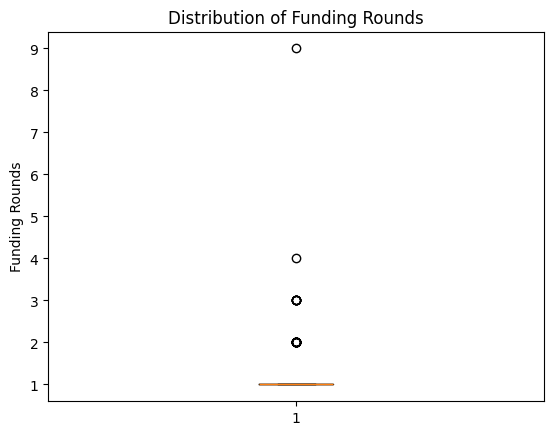

In [62]:
plt.boxplot(df['Funding_rounds'].dropna())
plt.ylabel('Funding Rounds')
plt.title('Distribution of Funding Rounds')
plt.show()

**Observation:** Most startups have one funding round. Higher values are statistical outliers but represent valid funding activity, so they are retained.

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               129 non-null    object 
 1   Category_list      123 non-null    object 
 2   Funding_total_usd  129 non-null    object 
 3   Funding_rounds     129 non-null    int64  
 4   State_code         126 non-null    float64
 5   Region             125 non-null    object 
 6   City               125 non-null    object 
 7   Founded_at         105 non-null    object 
 8   First_funding_at   129 non-null    object 
 9   Last_funding_at    129 non-null    object 
 10  Status             129 non-null    object 
 11  Outcome            129 non-null    object 
 12  Homepage_url       126 non-null    object 
 13  Permalink          129 non-null    object 
dtypes: float64(1), int64(1), object(12)
memory usage: 14.2+ KB


### Cleaning and Converting Funding Total

The `Funding_total_usd` attribute contains non-numeric entries such as `-`, which prevent direct numerical analysis. Therefore, the column is converted to a numeric data type using `pd.to_numeric()` with `errors='coerce'`. Invalid non-numeric entries are converted into missing values (`NaN`) so that they can be identified and handled appropriately.

In [64]:
df['Funding_total_usd'].head(5)

,Funding_total_usd
0,-
1,25000
2,100000000
3,10000
4,-


In [65]:
df['Funding_total_usd'] = pd.to_numeric(
    df['Funding_total_usd'].replace('-', pd.NA),
    errors='coerce'
)

In [66]:
df['Funding_total_usd'].head(5)

,Funding_total_usd
0,NaN
1,25000.0
2,100000000.0
3,10000.0
4,NaN


In [67]:
df['Funding_total_usd'].dtype

dtype('float64')

### Missing Value Analysis

Missing values are evaluated before deciding whether to fill, retain, or remove them.

In [68]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})
missing[missing['Missing_Count']>0]

,Missing_Count,Missing_Percentage
Category_list,6,4.65
Funding_total_usd,33,25.58
State_code,3,2.33
Region,4,3.10
City,4,3.10
Founded_at,24,18.60
Homepage_url,3,2.33


In [69]:
df['Funding_total_usd'].describe()

,Funding_total_usd
count,9.600000e+01
mean,1.735986e+07
std,3.704689e+07
min,8.000000e+03
25%,2.875000e+05
50%,2.990000e+06
75%,1.425000e+07
max,2.419833e+08


### Handling Missing Values

Missing categorical information is labeled as `Unknown`, while missing funding and founding-date values are retained to avoid introducing artificial data.

In [70]:
columns_to_fill = ['Category_list', 'Region', 'City']

df[columns_to_fill] = df[columns_to_fill].fillna('Unknown')

In [71]:
df.isnull().sum()

,0
Name,0
Category_list,0
Funding_total_usd,33
Funding_rounds,0
State_code,3
Region,0
City,0
Founded_at,24
First_funding_at,0
Last_funding_at,0


### Final Data Quality Check

The cleaned dataset is reviewed for data types, missing values, and duplicate records before analysis.

In [72]:
df.duplicated().sum()

np.int64(0)

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               129 non-null    object 
 1   Category_list      129 non-null    object 
 2   Funding_total_usd  96 non-null     float64
 3   Funding_rounds     129 non-null    int64  
 4   State_code         126 non-null    float64
 5   Region             129 non-null    object 
 6   City               129 non-null    object 
 7   Founded_at         105 non-null    object 
 8   First_funding_at   129 non-null    object 
 9   Last_funding_at    129 non-null    object 
 10  Status             129 non-null    object 
 11  Outcome            129 non-null    object 
 12  Homepage_url       126 non-null    object 
 13  Permalink          129 non-null    object 
dtypes: float64(2), int64(1), object(11)
memory usage: 14.2+ KB


In [74]:
df.to_excel('startup_funding_cleaned.xlsx', index=False)

### Preprocessing Summary

The dataset was systematically examined for missing values, duplicate records, inconsistent categorical values, invalid numerical values, incorrect data types, and potential outliers. No duplicate startup records were identified. Non-numeric entries in `Funding_total_usd` were converted into missing values to enable numerical analysis, while missing categorical information in selected attributes was represented as `Unknown`.

Potential outliers in funding-related attributes were examined using the IQR method. These observations were retained because they may represent genuine variation among startups rather than data-entry errors. Missing values that could not be reliably inferred from the available information were retained instead of introducing artificial values.

The resulting dataset is considered suitable for subsequent exploratory, statistical, and regression-based analysis, with remaining missing values handled appropriately within individual analyses when required.

### Exploratory Data Analysis and Statistical Analysis

After preprocessing the dataset, exploratory and statistical analysis is performed to understand the characteristics of the startups, examine funding patterns, compare successful and failed startups, and study relationships among important variables.

The analysis focuses on answering the project objectives using descriptive statistics, visualizations, statistical testing, and appropriate analytical techniques.

Descriptive Statistical Analysis

---



Descriptive statistics are used to summarize the main numerical characteristics of the startup dataset. Measures of central tendency and dispersion help in understanding the typical values, variability, and distribution of important numerical attributes before applying further statistical techniques.

In [75]:
# Select important numerical attributes for descriptive analysis
descriptive_columns = ['Funding_total_usd', 'Funding_rounds']

# Calculate descriptive statistics for each selected attribute
for column in descriptive_columns:

    data = df[column].dropna()


    print("DESCRIPTIVE STATISTICS FOR:", column)


    print("Count:", data.count())
    print("Mean:", data.mean())
    print("Median:", data.median())
    print("Mode:", data.mode().iloc[0])
    print("Minimum:", data.min())
    print("Maximum:", data.max())
    print("Range:", data.max() - data.min())
    print("Variance:", data.var())
    print("Standard Deviation:", data.std())
    print("Q1 (25th Percentile):", data.quantile(0.25))
    print("Q3 (75th Percentile):", data.quantile(0.75))
    print("IQR:", data.quantile(0.75) - data.quantile(0.25))

DESCRIPTIVE STATISTICS FOR: Funding_total_usd
Count: 96
Mean: 17359859.197916668
Median: 2990000.0
Mode: 10000000.0
Minimum: 8000.0
Maximum: 241983286.0
Range: 241975286.0
Variance: 1372471801760961.2
Standard Deviation: 37046886.53262189
Q1 (25th Percentile): 287500.0
Q3 (75th Percentile): 14250000.0
IQR: 13962500.0
DESCRIPTIVE STATISTICS FOR: Funding_rounds
Count: 129
Mean: 1.3565891472868217
Median: 1.0
Mode: 1
Minimum: 1
Maximum: 9
Range: 8
Variance: 0.8249757751937971
Standard Deviation: 0.9082817708144302
Q1 (25th Percentile): 1.0
Q3 (75th Percentile): 1.0
IQR: 0.0


#### Interpretation

The descriptive statistics show considerable variation in the funding received by startups. The mean total funding is approximately **$17.36 million**, while the median is only **$2.99 million**. The mean being substantially higher than the median indicates that the funding distribution is positively skewed, with a relatively small number of highly funded startups increasing the overall average.

Funding values range from **$8,000 to approximately $241.98 million**, with a high standard deviation of approximately **$37.05 million**, further indicating substantial variation in startup funding.

For `Funding_rounds`, the median and mode are both **1**, and the first and third quartiles are also 1. This indicates that most startups in the dataset completed only one funding round, while a relatively small number of startups underwent multiple funding rounds, with the maximum reaching **9 rounds**.

These results highlight the uneven nature of startup funding and provide a statistical foundation for further comparison of successful and failed startups.

 Startup Outcome Analysis

The distribution of startup outcomes is examined to understand the number and proportion of successful and failed startups in the dataset. This also helps determine whether the outcome classes are reasonably balanced before performing comparative and classification-based analysis.

In [76]:
# Count the number of startups in each outcome category
outcome_counts = df['Outcome'].value_counts()

# Calculate percentage distribution
outcome_percentage = df['Outcome'].value_counts(normalize=True) * 100

print("STARTUP OUTCOME DISTRIBUTION:")
print(outcome_counts)

print("\nOUTCOME PERCENTAGE:")
print(outcome_percentage.round(2))

STARTUP OUTCOME DISTRIBUTION:
Outcome
Failure    69
Success    60
Name: count, dtype: int64

OUTCOME PERCENTAGE:
Outcome
Failure    53.49
Success    46.51
Name: proportion, dtype: float64


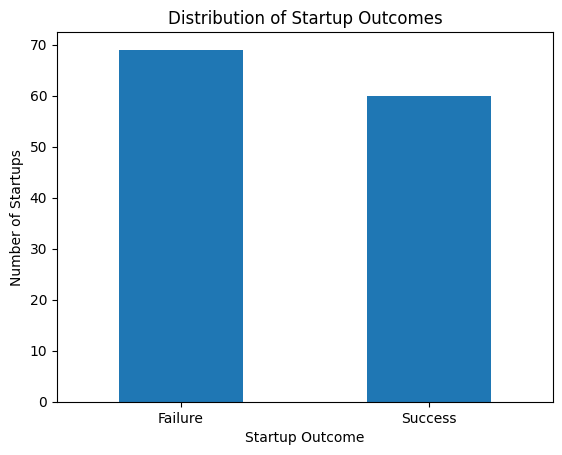

In [77]:
# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Create bar chart for startup outcomes
outcome_counts.plot(kind='bar')

plt.title('Distribution of Startup Outcomes')
plt.xlabel('Startup Outcome')
plt.ylabel('Number of Startups')
plt.xticks(rotation=0)

plt.show()

#### Interpretation

The dataset contains **69 failed startups and 60 successful startups**, corresponding to approximately **53.49% failures and 46.51% successes**.

The two outcome categories are relatively balanced, with only a small difference between the number of successful and failed startups. This balance is useful for comparative analysis and later classification-based techniques because neither outcome category overwhelmingly dominates the dataset.

### Funding Comparison: Successful vs Failed Startups

To investigate whether funding patterns differ according to startup outcome, the total funding received by successful and failed startups is compared using descriptive statistics. This analysis helps determine whether successful startups tend to show different funding characteristics from failed startups.

In [78]:
# Separate funding data based on startup outcome
successful_funding = df[df['Outcome'] == 'Success']['Funding_total_usd'].dropna()
failed_funding = df[df['Outcome'] == 'Failure']['Funding_total_usd'].dropna()

# Display number of available funding observations
print("Successful startups with funding data:", len(successful_funding))
print("Failed startups with funding data:", len(failed_funding))

# Compare descriptive funding statistics
print("\nSUCCESSFUL STARTUPS")
print("Mean Funding:", successful_funding.mean())
print("Median Funding:", successful_funding.median())
print("Standard Deviation:", successful_funding.std())

print("\nFAILED STARTUPS")
print("Mean Funding:", failed_funding.mean())
print("Median Funding:", failed_funding.median())
print("Standard Deviation:", failed_funding.std())

Successful startups with funding data: 47
Failed startups with funding data: 49

SUCCESSFUL STARTUPS
Mean Funding: 24696251.63829787
Median Funding: 7000000.0
Standard Deviation: 46660523.0532258

FAILED STARTUPS
Mean Funding: 10322911.346938776
Median Funding: 530000.0
Standard Deviation: 22948012.06713641


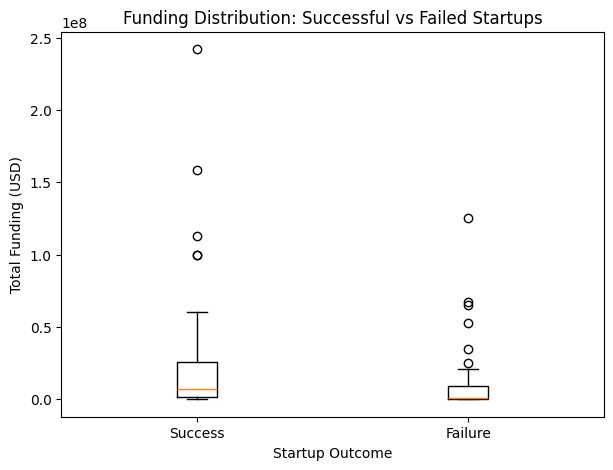

In [79]:
# Prepare funding data for visualization
success_data = df[df['Outcome'] == 'Success']['Funding_total_usd'].dropna()
failure_data = df[df['Outcome'] == 'Failure']['Funding_total_usd'].dropna()

# Create boxplot to compare funding distributions
plt.figure(figsize=(7, 5))

plt.boxplot(
    [success_data, failure_data],
    tick_labels=['Success', 'Failure']
)

plt.title('Funding Distribution: Successful vs Failed Startups')
plt.xlabel('Startup Outcome')
plt.ylabel('Total Funding (USD)')

plt.show()

#### Interpretation

The funding comparison shows a noticeable difference between successful and failed startups. Successful startups received an average funding of approximately **$24.70 million**, compared with approximately **$10.32 million** for failed startups.

The difference is also evident in the median funding values. Successful startups have a median funding of **$7.00 million**, whereas failed startups have a substantially lower median of approximately **$0.53 million**. This suggests that, within the available funding records, successful startups generally received higher levels of funding than failed startups.

The standard deviation is high for both groups, particularly for successful startups, indicating considerable variation in funding amounts and the presence of highly funded companies.

However, these descriptive differences alone do not establish whether the difference in funding between the two groups is statistically significant. This will be examined later using an appropriate hypothesis test.

### Relationship Between Funding Rounds and Total Funding

The relationship between the number of funding rounds and the total funding received by startups is examined to determine whether startups undergoing more funding rounds also tend to receive higher total funding. Pearson correlation is used to measure the direction and strength of the linear relationship between these two numerical variables.

In [80]:
# Select required variables and remove records with missing funding values
correlation_data = df[['Funding_rounds', 'Funding_total_usd']].dropna()

# Calculate Pearson correlation coefficient
correlation = correlation_data['Funding_rounds'].corr(
    correlation_data['Funding_total_usd']
)

print("Pearson Correlation between Funding Rounds and Total Funding:")
print(round(correlation, 4))

Pearson Correlation between Funding Rounds and Total Funding:
0.4385


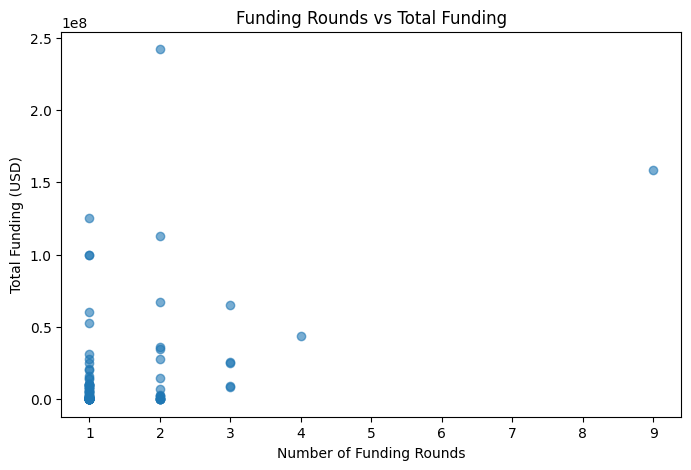

In [81]:
# Create scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    correlation_data['Funding_rounds'],
    correlation_data['Funding_total_usd'],
    alpha=0.6
)

plt.title('Funding Rounds vs Total Funding')
plt.xlabel('Number of Funding Rounds')
plt.ylabel('Total Funding (USD)')

plt.show()

#### Interpretation

The Pearson correlation coefficient between `Funding_rounds` and `Funding_total_usd` is approximately **0.4385**, indicating a **moderate positive linear relationship** between the two variables.

This suggests that startups with a greater number of funding rounds tend to have higher total funding. However, the relationship is not very strong, indicating that the number of funding rounds alone does not fully explain the variation in total funding received by startups.

The scatter plot also helps visualize this relationship and the variability in funding amounts across startups. This relationship will be examined further using regression analysis later in the project.

### Sampling and Central Limit Theorem

The Central Limit Theorem (CLT) is demonstrated using `Funding_total_usd` to examine how the distribution of sample means behaves when repeated random samples are drawn from the startup dataset. Multiple samples are generated with replacement, and their mean funding values are compared with the mean funding of the complete dataset.

In [82]:
# Sampling to illustrate the Central Limit Theorem
import numpy as np

# Use a fixed seed so the example is reproducible
np.random.seed(42)

# Choose a few sample sizes to watch how the distribution tightens
sample_sizes = [30, 50, 100]          # n = number of startups per sample
n_bootstrap = 1000                    # how many random samples to draw for each n

# Store the means of each bootstrap sample
sample_means = {}                     # key = sample size, value = array of means

for n in sample_sizes:
    means = []                        # will hold the mean of each bootstrap sample
    for _ in range(n_bootstrap):
        # Randomly pick n rows (with replacement – typical for CLT demos)
        sample = df.sample(n=n, replace=True)
        # Compute the average funding for this sample
        means.append(sample['Funding_total_usd'].mean())
    sample_means[n] = np.array(means)   # store as a NumPy array for easy analysis

#### Visualization of the Sampling Distribution

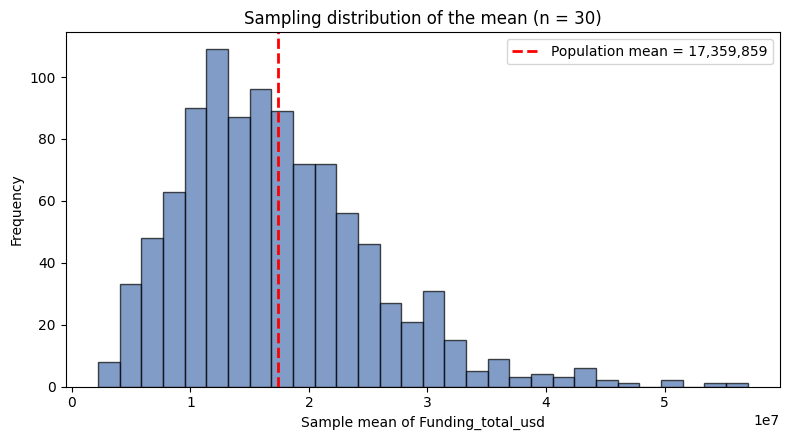

In [83]:
# Plot the histogram of sample means (n = 30)
import matplotlib.pyplot as plt

# Grab the means for the smallest sample size (30) for a clear view
means_n30 = sample_means[30]

# Plot a histogram of these means
plt.figure(figsize=(8, 4.5))
plt.hist(means_n30, bins=30, edgecolor='black', alpha=0.7, color='#4C72B0')
# Add a vertical line for the true population mean (computed from the full dataset)
pop_mean = df['Funding_total_usd'].mean()
plt.axvline(pop_mean, color='red', linestyle='--', linewidth=2,
            label=f'Population mean = {pop_mean:,.0f}')

plt.title('Sampling distribution of the mean (n = 30)')
plt.xlabel('Sample mean of Funding_total_usd')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

#### Comparison of Sample and Population Statistics

In [84]:
# Compare population mean with the mean of the n=30 samples
pop_mean = df['Funding_total_usd'].mean()
sample_mean_n30 = sample_means[30].mean()   # average of the 1 000 bootstrap means

print(f"Population mean (full data)   : {pop_mean:,.0f}")
print(f"Mean of sample means (n=30)   : {sample_mean_n30:,.0f}")
print(f"Difference (should be ≈ 0)    : {sample_mean_n30 - pop_mean:,.0f}")

Population mean (full data)   : 17,359,859
Mean of sample means (n=30)   : 17,317,233
Difference (should be ≈ 0)    : -42,627


#### Interpretation

The mean of the repeated sample means is approximately **$17.32 million**, which is very close to the overall dataset mean of approximately **$17.36 million**. The difference between the two is relatively small compared with the overall scale of startup funding.

The sampling distribution also becomes more concentrated around the population mean, illustrating the Central Limit Theorem and showing how repeated sampling can provide stable estimates of the population mean.

###  Confidence Interval for Mean Startup Funding

A 95% confidence interval is estimated for the mean startup funding using a random sample of 30 startups. Since the population standard deviation is not assumed to be known, the t-distribution is used to calculate the interval.

In [85]:
# 95 % confidence interval for the mean (n = 30)
import scipy.stats as stats          # for the t‑distribution quantile

# Re‑create a single reproducible sample of size 30 (no replacement)
sample_n30 = df.sample(n=30, replace=False, random_state=42)

# Sample statistics
sample_mean_30 = sample_n30['Funding_total_usd'].mean()
sample_std_30  = sample_n30['Funding_total_usd'].std(ddof=1)   # unbiased estimator

# Standard error of the mean
SE = sample_std_30 / np.sqrt(30)

# t‑critical value for a two‑sided 95 % CI (df = n‑1)
alpha = 0.05
degrees_of_freedom = 30 - 1
t_critical = stats.t.ppf(1 - alpha/2, degrees_of_freedom)

# Confidence limits
ci_lower = sample_mean_30 - t_critical * SE
ci_upper = sample_mean_30 + t_critical * SE

# Display the results
print(f"95 % CI for the mean (n=30): [{ci_lower:,.0f}, {ci_upper:,.0f}]")
print(f"t_critical = {t_critical:.3f},  SE = {SE:.2f}")

95 % CI for the mean (n=30): [2,525,044, 22,723,116]
t_critical = 2.045,  SE = 4937849.31


#### Interpretation

For the selected sample of 30 startups, the estimated **95% confidence interval for mean funding ranges from approximately $2.53 million to $22.72 million**.

The relatively wide interval reflects the substantial variability in startup funding values observed in the dataset. The interval provides a range of plausible values for the mean funding level based on the selected sample.

###  Hypothesis Testing: Funding of Successful vs Failed Startups

The descriptive analysis showed that successful startups have higher average funding than failed startups. An independent two-sample Welch's t-test is therefore used to determine whether the observed difference in mean funding between the two groups is statistically significant.

**Null Hypothesis (H₀):** There is no significant difference in the mean total funding of successful and failed startups.

**Alternative Hypothesis (H₁):** There is a significant difference in the mean total funding of successful and failed startups.

The significance level is set at **α = 0.05**.

In [86]:
# Two‑sample t‑test: funding of Success vs Failure startups
import scipy.stats as stats

# Separate the two outcome groups and drop missing funding values
success = df[df['Outcome'] == 'Success']['Funding_total_usd'].dropna()
failure = df[df['Outcome'] == 'Failure']['Funding_total_usd'].dropna()

# Descriptive stats for each group
print(f"Success startups : n = {len(success)}, mean = {success.mean():,.0f}")
print(f"Failure startups : n = {len(failure)}, mean = {failure.mean():,.0f}")
print()
print(f"Std dev Success : {success.std(ddof=1):,.0f}")
print(f"Std dev Failure : {failure.std(ddof=1):,.0f}")

# Independent two‑sample t‑test (assumes unequal variances – Welch’s test)
t_stat, p_value = stats.ttest_ind(success, failure, equal_var=False)

print()
print(f"t‑statistic = {t_stat:.3f}")
print(f"p‑value     = {p_value:.4f}")

# Interpretation
alpha = 0.05
if p_value < alpha:
    print("Result: Reject H0 — mean funding differs significantly between Success and Failure startups.")
else:
    print("Result: Fail to reject H0 — no significant difference in mean funding.")

Success startups : n = 47, mean = 24,696,252
Failure startups : n = 49, mean = 10,322,911

Std dev Success : 46,660,523
Std dev Failure : 22,948,012

t‑statistic = 1.903
p‑value     = 0.0614
Result: Fail to reject H0 — no significant difference in mean funding.


#### Interpretation

The Welch's independent two-sample t-test produced a **t-statistic of 1.903** and a **p-value of 0.0614**.

Since the p-value (**0.0614**) is greater than the significance level of **0.05**, the null hypothesis is **not rejected**. Therefore, at the 5% significance level, there is insufficient statistical evidence to conclude that the mean total funding of successful startups is significantly different from that of failed startups.

Although successful startups have a considerably higher observed mean funding (approximately **$24.70 million**) than failed startups (approximately **$10.32 million**), the difference is **not statistically significant at α = 0.05** based on this test.

This illustrates an important distinction between a descriptive difference and statistical significance: a noticeable difference in sample means does not necessarily provide sufficient evidence of a difference at the population level.

###  Chi-Square Test of Association: Startup Outcome and Region

A Chi-Square Test of Independence is used to examine whether startup outcome (Success or Failure) is associated with the geographical region of the startup.

**Null Hypothesis (H₀):** Startup outcome and region are independent; there is no significant association between them.

**Alternative Hypothesis (H₁):** Startup outcome and region are associated.

The significance level is set at **α = 0.05**.

In [87]:
# Build a contingency table: Outcome × Region
# This cross-tabulates startup outcome (Success/Failure) against region
# so we can test whether outcome depends on where the startup is based.

contingency = pd.crosstab(df['Outcome'], df['Region'])

# Show the raw counts
print(contingency)


Region   Ahmedabad  Bangalore  Chandigarh  Chennai  Coimbatore  Delhi  \
Outcome                                                                 
Failure          2         18           1        5           1      2   
Success          2         21           0        4           0      0   

Region   Ghaziabad  Haryana  Hyderabad  IND - Other  Jaipur  Kolkata  Mumbai  \
Outcome                                                                        
Failure          1        0          3            0       0        1      15   
Success          0        1          3            1       1        0      13   

Region   New Delhi  Pune  Thane  Trivandrum  Unknown  Vellore  
Outcome                                                        
Failure         14     0      1           0        4        1  
Success         11     2      0           1        0        0  


In [88]:
# Chi-square test
from scipy.stats import chi2_contingency

# chi2_contingency returns: statistic, p-value, dof, expected frequencies
chi2, p_value, dof, expected = chi2_contingency(contingency)

print(f"Chi-square statistic = {chi2:.3f}")
print(f"p-value              = {p_value:.4f}")
print(f"Degrees of freedom   = {dof}")
print()
print("Expected frequencies (first few cells):")
print(expected[:3, :3])

Chi-square statistic = 18.306
p-value              = 0.4357
Degrees of freedom   = 18

Expected frequencies (first few cells):
[[ 2.13953488 20.86046512  0.53488372]
 [ 1.86046512 18.13953488  0.46511628]]


In [89]:
# Interpretation at α = 0.05
alpha = 0.05

if p_value < alpha:
    print("Reject H₀: Startup outcome depends on Region (statistically significant association).")
else:
    print("Fail to reject H₀: No sufficient evidence that outcome depends on Region.")

Fail to reject H₀: No sufficient evidence that outcome depends on Region.


#### Interpretation

The Chi-Square Test of Independence produced a **Chi-square statistic of 18.306** with **18 degrees of freedom** and a **p-value of 0.4357**.

Since the p-value (**0.4357**) is greater than the significance level of **0.05**, the null hypothesis is not rejected. Therefore, the available data does not provide sufficient statistical evidence to conclude that startup outcome is associated with geographical region.

However, some expected frequencies in the contingency table are below 5 because several regions contain relatively few startups. Therefore, the Chi-square approximation should be interpreted with caution, and the result should not be considered strong evidence that geographical region has no relationship with startup outcome.



```
`# This is formatted as code`
```
## Principal Component Analysis (PCA)

Principal Component Analysis (PCA) is applied to reduce the dimensionality of the numerical startup features while retaining as much information as possible. Since PCA is sensitive to differences in measurement scales, the selected numerical features are standardized before applying the technique.

For this analysis, `Funding_total_usd` and `Funding_rounds` are used as meaningful numerical features. Records with missing values in the selected features are excluded from the PCA rather than assigning artificial values.

In [90]:
# Import required libraries for PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt

# Select meaningful numerical features for PCA
pca_data = df[
    ['Funding_total_usd', 'Funding_rounds', 'Outcome']
].dropna().copy()

print("Number of observations used for PCA:", len(pca_data))
print("Features used: Funding_total_usd and Funding_rounds")

Number of observations used for PCA: 96
Features used: Funding_total_usd and Funding_rounds


In [91]:
# Select the numerical features
X_pca_features = pca_data[
    ['Funding_total_usd', 'Funding_rounds']
]

# Standardize the features so that both contribute fairly to PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca_features)

In [92]:
# Apply PCA and retain two principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame containing the principal components
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

# Add startup outcome for comparison in visualization
pca_df['Outcome'] = pca_data['Outcome'].reset_index(drop=True)

# Display explained variance
print("Explained Variance Ratio:")
print("PC1:", round(pca.explained_variance_ratio_[0], 4))
print("PC2:", round(pca.explained_variance_ratio_[1], 4))

print(
    "Total Variance Explained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

Explained Variance Ratio:
PC1: 0.7193
PC2: 0.2807
Total Variance Explained: 1.0


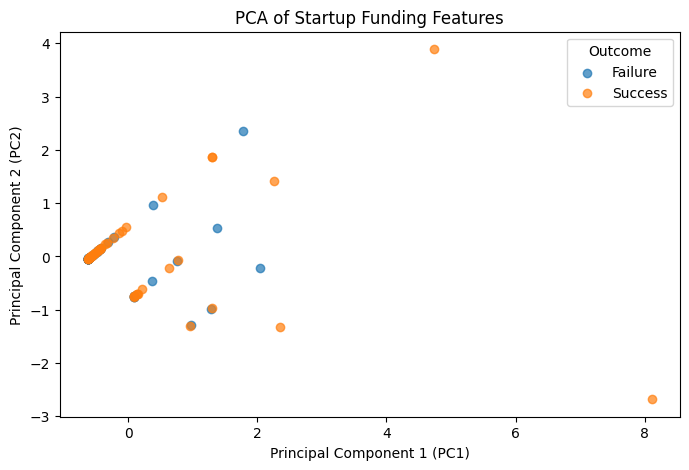

In [93]:
# Plot PCA components according to startup outcome
plt.figure(figsize=(8, 5))

for outcome in pca_df['Outcome'].unique():

    subset = pca_df[pca_df['Outcome'] == outcome]

    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=outcome,
        alpha=0.7
    )

plt.title('PCA of Startup Funding Features')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.legend(title='Outcome')

plt.show()

#### Interpretation

The PCA results show that **Principal Component 1 (PC1) explains approximately 71.93% of the total variance**, while **Principal Component 2 (PC2) explains approximately 28.07%**.

Therefore, PC1 captures most of the variation present in the selected funding-related features (`Funding_total_usd` and `Funding_rounds`). Together, the two principal components explain **100% of the variance**, which is expected because two principal components were retained from two original numerical features.

The PCA visualization represents the startups in terms of these transformed components and allows the distribution of successful and failed startups to be visually compared in the reduced feature space.

###  Linear Discriminant Analysis (LDA)

Linear Discriminant Analysis (LDA) is applied as a supervised technique to examine whether the available funding-related features can distinguish between successful and failed startups.

Unlike PCA, which does not use the outcome labels while creating components, LDA uses the known startup outcome to find a linear combination of features that provides separation between the Success and Failure classes.

For this analysis, `Funding_total_usd` and `Funding_rounds` are used as predictor variables, while `Outcome` represents the target class.

In [94]:
# Import required libraries for LDA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
import numpy as np

# Select predictor variables and target
lda_data = df[
    ['Funding_total_usd', 'Funding_rounds', 'Outcome']
].dropna().copy()

# Separate predictors and target
X_lda = lda_data[
    ['Funding_total_usd', 'Funding_rounds']
]

y_lda = lda_data['Outcome']

print("Number of observations used for LDA:", len(lda_data))
print("Predictor variables: Funding_total_usd, Funding_rounds")
print("\nOutcome distribution:")
print(y_lda.value_counts())

Number of observations used for LDA: 96
Predictor variables: Funding_total_usd, Funding_rounds

Outcome distribution:
Outcome
Failure    49
Success    47
Name: count, dtype: int64


In [95]:
# Standardize the predictor variables
scaler_lda = StandardScaler()

X_lda_scaled = scaler_lda.fit_transform(X_lda)

In [96]:
# Create the LDA model
lda_model = LinearDiscriminantAnalysis()

# Evaluate the model using 5-fold cross-validation
lda_cv_scores = cross_val_score(
    lda_model,
    X_lda_scaled,
    y_lda,
    cv=5
)

print("Individual Fold Accuracies:")
print(np.round(lda_cv_scores, 4))

print(
    "\nMean Cross-Validated Accuracy:",
    round(lda_cv_scores.mean(), 4)
)

Individual Fold Accuracies:
[0.5    0.4211 0.7368 0.5263 0.5789]

Mean Cross-Validated Accuracy: 0.5526


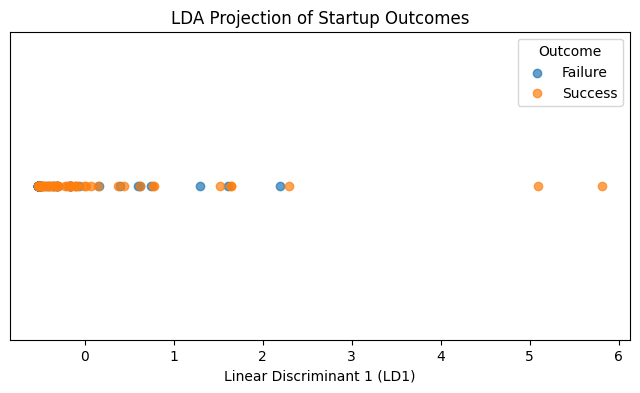

In [97]:
# Fit LDA using the available data
lda_model.fit(X_lda_scaled, y_lda)

# Transform the two original features into one discriminant component
X_lda_component = lda_model.transform(X_lda_scaled)

# Create a DataFrame for visualization
lda_plot_data = pd.DataFrame({
    'LD1': X_lda_component[:, 0],
    'Outcome': y_lda.reset_index(drop=True)
})

# Plot the first linear discriminant
plt.figure(figsize=(8, 4))

for outcome in lda_plot_data['Outcome'].unique():

    subset = lda_plot_data[
        lda_plot_data['Outcome'] == outcome
    ]

    plt.scatter(
        subset['LD1'],
        [0] * len(subset),
        label=outcome,
        alpha=0.7
    )

plt.title('LDA Projection of Startup Outcomes')
plt.xlabel('Linear Discriminant 1 (LD1)')
plt.yticks([])
plt.legend(title='Outcome')

plt.show()

#### Interpretation

Linear Discriminant Analysis was performed using **96 startups** with complete funding information. The two outcome classes were nearly balanced, with **49 failed startups and 47 successful startups**.

Using 5-fold cross-validation, the LDA model achieved individual fold accuracies ranging from approximately **42.11% to 73.68%**, with an overall mean cross-validated accuracy of approximately **55.26%**.

This relatively modest accuracy suggests that `Funding_total_usd` and `Funding_rounds` alone provide limited ability to distinguish between successful and failed startups. Therefore, startup outcome is likely associated with additional factors that are not fully represented by these two funding-related variables.

The LDA projection provides a visual representation of the separation between the Success and Failure classes along the first linear discriminant (LD1).

### Simple Linear Regression

Simple Linear Regression is applied to examine how the number of funding rounds is related to the total funding received by a startup.

In this analysis:

- **Independent variable (X):** `Funding_rounds`
- **Dependent variable (Y):** `Funding_total_usd`

The regression model estimates the change in total funding associated with an increase of one funding round. The coefficient of determination (R²) is used to evaluate how much of the variation in total funding is explained by the number of funding rounds.

In [98]:
import statsmodels.api as sm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Select predictor and target, drop missing values
reg_df = df[['Funding_rounds', 'Funding_total_usd']].dropna()

print("Number of usable observations:", len(reg_df))
print(reg_df.head())

Number of usable observations: 96
   Funding_rounds  Funding_total_usd
1               1            25000.0
2               1        100000000.0
3               1            10000.0
5               1         10000000.0
6               1           250000.0


In [99]:
# Build the design matrix with a constant column
X = sm.add_constant(reg_df['Funding_rounds'])
y = reg_df['Funding_total_usd']

In [100]:
# Fit Ordinary Least Squares model
model = sm.OLS(y, X).fit()
print(model.summary())

# Pull out the most useful numbers
print("Intercept (const):", round(model.params['const'], 2))
print("Slope (Funding_rounds):", round(model.params['Funding_rounds'], 2))
print("R-squared:", round(model.rsquared, 4))
print("p-value for Funding_rounds:", round(model.pvalues['Funding_rounds'], 4))

                            OLS Regression Results                            
Dep. Variable:      Funding_total_usd   R-squared:                       0.192
Model:                            OLS   Adj. R-squared:                  0.184
Method:                 Least Squares   F-statistic:                     22.38
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           7.86e-06
Time:                        19:52:27   Log-Likelihood:                -1798.5
No. Observations:                  96   AIC:                             3601.
Df Residuals:                      94   BIC:                             3606.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const          -5.467e+06   5.91e+06     -0.

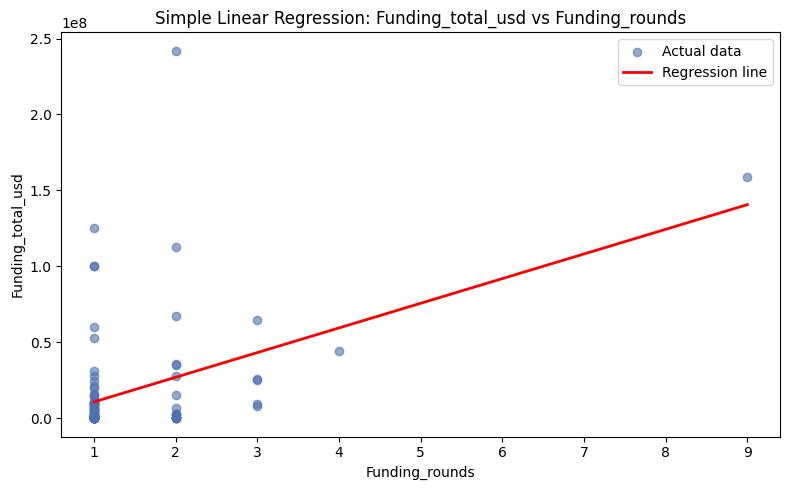

In [101]:
# Scatter plot with fitted regression line
plt.figure(figsize=(8, 5))
plt.scatter(reg_df['Funding_rounds'], y, alpha=0.6, color='#4C72B0', label='Actual data')

x_line = np.linspace(reg_df['Funding_rounds'].min(), reg_df['Funding_rounds'].max(), 100)
X_line = sm.add_constant(x_line)
y_pred = model.predict(X_line)

plt.plot(x_line, y_pred, color='red', linewidth=2, label='Regression line')
plt.title('Simple Linear Regression: Funding_total_usd vs Funding_rounds')
plt.xlabel('Funding_rounds')
plt.ylabel('Funding_total_usd')
plt.legend()
plt.tight_layout()
plt.show()

#### Interpretation

The simple linear regression analysis shows a positive relationship between the number of funding rounds and total startup funding.

The estimated slope for `Funding_rounds` is approximately **$16.23 million**. This indicates that, according to the fitted linear model, each additional funding round is associated with an average increase of approximately **$16.23 million in total funding**.

The model has an **R² value of 0.1923**, indicating that approximately **19.23% of the variation in total funding** is explained by the number of funding rounds alone. Therefore, although funding rounds are related to total funding, a large proportion of funding variation is associated with other factors not included in this simple model.

The p-value for `Funding_rounds` is extremely small (**p < 0.001**), indicating that the observed linear relationship between funding rounds and total funding is statistically significant.

The negative intercept should be interpreted cautiously because a startup with zero funding rounds lies outside the meaningful range of the observed data, where the minimum number of funding rounds is one.

### Multiple Linear Regression

Multiple Linear Regression is applied to examine how multiple startup characteristics are jointly related to total funding received.

For this analysis, two meaningful numerical predictors are used:

- `Funding_rounds`: Number of funding rounds completed by the startup.
- `Years_to_first_funding`: Approximate time between the startup's founding date and its first recorded funding date.

The dependent variable is `Funding_total_usd`.

This model extends the simple linear regression by examining whether multiple startup characteristics together help explain variation in total funding.

In [102]:
import statsmodels.api as sm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Convert relevant date columns to datetime format
df['Founded_at'] = pd.to_datetime(
    df['Founded_at'],
    errors='coerce'
)

df['First_funding_at'] = pd.to_datetime(
    df['First_funding_at'],
    errors='coerce'
)

# Calculate approximate years between founding and first funding
df['Years_to_first_funding'] = (
    (df['First_funding_at'] - df['Founded_at']).dt.days / 365.25
)

# Select variables required for multiple linear regression
mlr_df = df[
    ['Funding_rounds', 'Years_to_first_funding', 'Funding_total_usd']
].dropna()

# Remove records with inconsistent date order for this analysis only
mlr_df = mlr_df[
    mlr_df['Years_to_first_funding'] >= 0
].copy()

print("Number of usable observations:", len(mlr_df))

print("\nFirst 5 observations:")
print(mlr_df.head())

Number of usable observations: 69

First 5 observations:
   Funding_rounds  Years_to_first_funding  Funding_total_usd
2               1               18.759754        100000000.0
5               1                5.489391         10000000.0
6               1                2.236824           250000.0
8               2                0.870637          2500000.0
9               1                1.062286         10000000.0


**Data Consistency Decision:** While deriving `Years_to_first_funding`, 8 records were found where the recorded first funding date occurred before the recorded founding date. Such negative intervals are not meaningful for this derived feature and may reflect inconsistencies in the source records. Therefore, these records are excluded **only from the multiple linear regression analysis** and are not removed from the main dataset.

In [103]:
# Check whether any first funding date occurs before the founding date
negative_years = (mlr_df['Years_to_first_funding'] < 0).sum()

print(
    "Records where first funding date is before founding date:",
    negative_years
)

Records where first funding date is before founding date: 0


In [104]:
# Build the design matrix using the two predictor variables
X = sm.add_constant(
    mlr_df[['Funding_rounds', 'Years_to_first_funding']]
)

# Define the dependent variable
y = mlr_df['Funding_total_usd']

In [105]:
# Fit Ordinary Least Squares model
mlr_model = sm.OLS(y, X).fit()
print(mlr_model.summary())

                            OLS Regression Results                            
Dep. Variable:      Funding_total_usd   R-squared:                       0.560
Model:                            OLS   Adj. R-squared:                  0.547
Method:                 Least Squares   F-statistic:                     42.02
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           1.70e-12
Time:                        19:52:27   Log-Likelihood:                -1257.6
No. Observations:                  69   AIC:                             2521.
Df Residuals:                      66   BIC:                             2528.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                  -1.99

In [106]:
# Display the most useful multiple regression results

print(
    "Intercept (const):",
    round(mlr_model.params['const'], 2)
)

print(
    "Coefficient - Funding_rounds:",
    round(mlr_model.params['Funding_rounds'], 2)
)

print(
    "Coefficient - Years_to_first_funding:",
    round(mlr_model.params['Years_to_first_funding'], 2)
)

print(
    "p-value - Funding_rounds:",
    round(mlr_model.pvalues['Funding_rounds'], 4)
)

print(
    "p-value - Years_to_first_funding:",
    round(mlr_model.pvalues['Years_to_first_funding'], 4)
)

print("R-squared:", round(mlr_model.rsquared, 4))
print("Adjusted R-squared:", round(mlr_model.rsquared_adj, 4))
print("Overall model p-value:", mlr_model.f_pvalue)

Intercept (const): -19984209.97
Coefficient - Funding_rounds: 17207885.75
Coefficient - Years_to_first_funding: 2347388.0
p-value - Funding_rounds: 0.0
p-value - Years_to_first_funding: 0.0
R-squared: 0.5601
Adjusted R-squared: 0.5468
Overall model p-value: 1.7022658907052793e-12


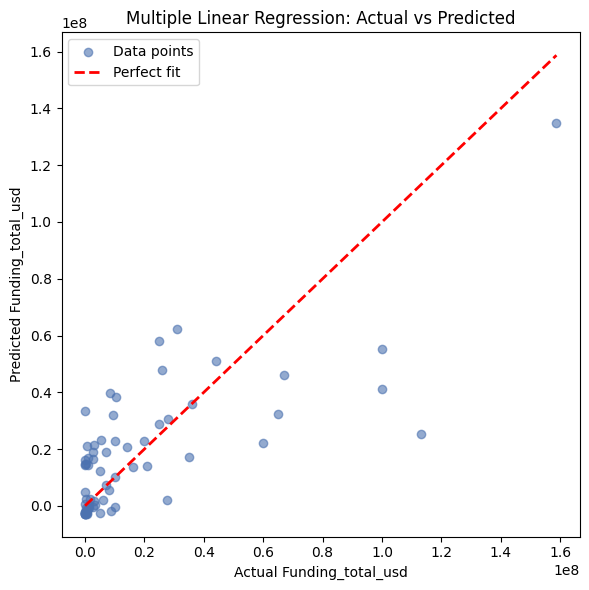

In [107]:
# Plot actual vs predicted Funding_total_usd
y_pred = mlr_model.predict(X)

plt.figure(figsize=(6, 6))
plt.scatter(y, y_pred, alpha=0.6, color='#4C72B0', label='Data points')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', linewidth=2, label='Perfect fit')
plt.xlabel('Actual Funding_total_usd')
plt.ylabel('Predicted Funding_total_usd')
plt.title('Multiple Linear Regression: Actual vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

#### Interpretation

The multiple linear regression model uses `Funding_rounds` and `Years_to_first_funding` to explain variation in `Funding_total_usd`.

The model achieved an **R² of 0.560**, indicating that approximately **56.0% of the variation in total startup funding** is explained jointly by the two predictor variables. The adjusted R² is **0.547**, showing that the model retains substantial explanatory power after accounting for the number of predictors.

The coefficient for `Funding_rounds` is approximately **$17.21 million** and is statistically significant (**p < 0.001**). Holding `Years_to_first_funding` constant, an additional funding round is associated with an estimated increase of approximately **$17.21 million in total funding**.

The coefficient for `Years_to_first_funding` is approximately **$2.35 million** and is also statistically significant (**p < 0.001**). Within this fitted model, a one-year increase in the recorded time between founding and first funding is associated with approximately **$2.35 million higher total funding**, while holding the number of funding rounds constant.

The overall regression model is statistically significant (**p < 0.001**). Compared with the simple linear regression model, which explained approximately **19.23%** of funding variation, the multiple regression model explains a substantially larger proportion of the variation.

These relationships represent statistical associations within the available dataset and should not be interpreted as evidence of causation.

In [108]:
# Import required libraries
import statsmodels.api as sm
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

# Select variables required for logistic regression
logit_df = df[
    ['Funding_total_usd', 'Funding_rounds', 'Outcome']
].dropna().copy()

print("Number of observations used:", len(logit_df))

print("\nOutcome distribution:")
print(logit_df['Outcome'].value_counts())

Number of observations used: 96

Outcome distribution:
Outcome
Failure    49
Success    47
Name: count, dtype: int64


In [109]:
# Encode the target variable
# Success = 1 and Failure = 0
logit_df['Outcome_bin'] = (
    logit_df['Outcome'] == 'Success'
).astype(int)

# Define predictor variables
X_logit = logit_df[
    ['Funding_total_usd', 'Funding_rounds']
]

# Define target variable
y_logit = logit_df['Outcome_bin']

print(logit_df[
    ['Funding_total_usd', 'Funding_rounds', 'Outcome', 'Outcome_bin']
].head())

   Funding_total_usd  Funding_rounds  Outcome  Outcome_bin
1            25000.0               1  Failure            0
2        100000000.0               1  Success            1
3            10000.0               1  Failure            0
5         10000000.0               1  Success            1
6           250000.0               1  Success            1


In [110]:
# Standardize predictor variables
scaler_logit = StandardScaler()

X_logit_scaled = scaler_logit.fit_transform(X_logit)

# Convert standardized values back to a DataFrame
X_logit_scaled = pd.DataFrame(
    X_logit_scaled,
    columns=['Funding_total_usd', 'Funding_rounds'],
    index=X_logit.index
)

# Add constant for the intercept
X_logit_scaled = sm.add_constant(X_logit_scaled)

In [111]:
# Fit the binary logistic regression model
logit_model = sm.Logit(
    y_logit,
    X_logit_scaled
)

logit_result = logit_model.fit(disp=False)

# Display complete model summary
print(logit_result.summary())

                           Logit Regression Results                           
Dep. Variable:            Outcome_bin   No. Observations:                   96
Model:                          Logit   Df Residuals:                       93
Method:                           MLE   Df Model:                            2
Date:                Mon, 23 Nov 2026   Pseudo R-squ.:                 0.03537
Time:                        19:52:28   Log-Likelihood:                -64.168
converged:                       True   LL-Null:                       -66.521
Covariance Type:            nonrobust   LLR p-value:                   0.09509
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.0122      0.212     -0.057      0.954      -0.428       0.404
Funding_total_usd     0.4166      0.302      1.379      0.168      -0.175       1.009
Funding_rounds        0.

In [112]:
# Display coefficients, p-values and odds ratios

print("LOGISTIC REGRESSION RESULTS\n")

for variable in logit_result.params.index:

    coefficient = logit_result.params[variable]
    p_value = logit_result.pvalues[variable]
    odds_ratio = np.exp(coefficient)

    print(variable)
    print("  Coefficient:", round(coefficient, 4))
    print("  p-value:", round(p_value, 4))
    print("  Odds Ratio:", round(odds_ratio, 4))
    print()

LOGISTIC REGRESSION RESULTS

const
  Coefficient: -0.0122
  p-value: 0.9543
  Odds Ratio: 0.9879

Funding_total_usd
  Coefficient: 0.4166
  p-value: 0.1679
  Odds Ratio: 1.5168

Funding_rounds
  Coefficient: 0.2361
  p-value: 0.4626
  Odds Ratio: 1.2664



In [113]:
# Calculate predicted probabilities of startup success
pred_prob = logit_result.predict(X_logit_scaled)

# Convert probabilities into predicted classes
# Probability >= 0.5 is classified as Success
pred_label = (pred_prob >= 0.5).astype(int)

# Calculate classification accuracy
accuracy = accuracy_score(
    y_logit,
    pred_label
)

# Generate confusion matrix
cm = confusion_matrix(
    y_logit,
    pred_label
)

print(
    "Classification Accuracy:",
    round(accuracy, 4)
)

print("\nConfusion Matrix:")
print(cm)

Classification Accuracy: 0.5729

Confusion Matrix:
[[41  8]
 [33 14]]


#### Interpretation

The logistic regression model was used to examine whether total funding and the number of funding rounds are associated with the probability of startup success.

For `Funding_total_usd`, the coefficient is **0.4166** with an odds ratio of approximately **1.52**. Since the predictor was standardized, this suggests that a one-standard-deviation increase in total funding is associated with approximately **1.52 times higher estimated odds of startup success**, while holding funding rounds constant. However, the corresponding p-value is **0.1679**, which is greater than 0.05, so this relationship is not statistically significant at the 5% level.

For `Funding_rounds`, the coefficient is **0.2361** with an odds ratio of approximately **1.27**. This indicates a positive estimated association with startup success, but its p-value of **0.4626** is also greater than 0.05 and therefore not statistically significant.

The model achieved a classification accuracy of approximately **57.29%**. From the confusion matrix, the model correctly classified **41 failed startups and 14 successful startups**, while **8 failed startups were incorrectly classified as successful and 33 successful startups were incorrectly classified as failed**.

Overall, the model provides only modest classification performance. The results suggest that total funding and number of funding rounds alone are not sufficient to reliably distinguish successful startups from failed startups, and additional startup characteristics may be required for stronger prediction.

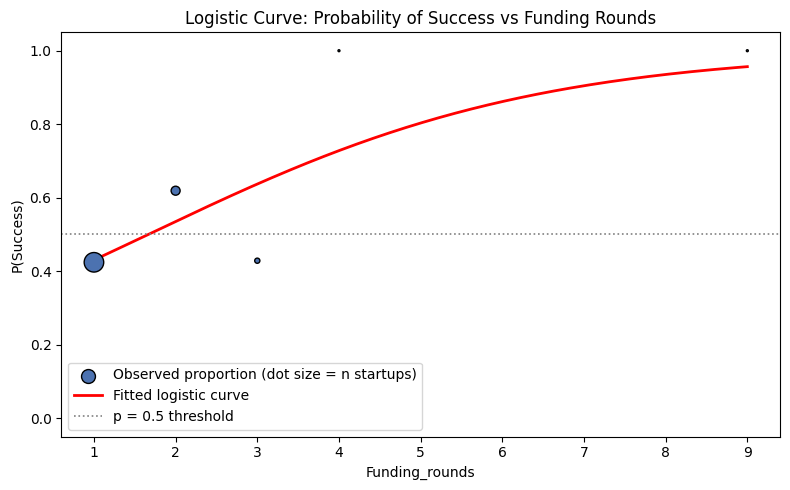

In [114]:
# Plot the fitted logistic curve (single predictor)
# A curve is only readable with one predictor, so we fit a
# small single-variable logistic model for the plot.

curve_df = df[['Funding_rounds', 'Outcome']].dropna().copy()
curve_df['Success'] = (curve_df['Outcome'] == 'Success').astype(int)

X_curve = sm.add_constant(curve_df['Funding_rounds'])
curve_model = sm.Logit(curve_df['Success'], X_curve).fit(disp=False)

# Smooth grid of funding-round values for the fitted curve
x_grid  = np.linspace(curve_df['Funding_rounds'].min(),
                      curve_df['Funding_rounds'].max(), 200)
p_grid  = curve_model.predict(sm.add_constant(x_grid))

# Observed success proportion at each actual round count
obs = curve_df.groupby('Funding_rounds')['Success'].agg(['mean', 'count'])

plt.figure(figsize=(8, 5))

# Observed points, sized by number of startups at that round count
plt.scatter(obs.index, obs['mean'], s=obs['count'] * 2,
            color='#4C72B0', edgecolor='k', zorder=3,
            label='Observed proportion (dot size = n startups)')

# Fitted logistic curve
plt.plot(x_grid, p_grid, color='red', linewidth=2,
         label='Fitted logistic curve')

plt.axhline(0.5, color='gray', linestyle=':', linewidth=1.2,
            label='p = 0.5 threshold')

plt.title('Logistic Curve: Probability of Success vs Funding Rounds')
plt.xlabel('Funding_rounds')
plt.ylabel('P(Success)')
plt.ylim(-0.05, 1.05)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

## Findings, Limitations and Conclusion

###  Key Findings

The analysis produced the following major findings:

1. **Startup funding shows substantial variability.**  
   The mean total funding is approximately **$17.36 million**, while the median is only **$2.99 million**, indicating a positively skewed funding distribution. A relatively small number of highly funded startups substantially increase the overall average.

2. **The dataset contains relatively balanced startup outcomes.**  
   Among the 129 startups, **69 (53.49%) are classified as Failure and 60 (46.51%) as Success**, providing a reasonably balanced basis for comparative and classification-based analysis.

3. **Successful startups show higher funding descriptively.**  
   Successful startups with available funding data received an average of approximately **$24.70 million**, compared with approximately **$10.32 million** for failed startups. Their median funding values also differ considerably, at approximately **$7.00 million for successful startups and $0.53 million for failed startups**.

4. **The observed funding difference was not statistically significant at the 5% level.**  
   Welch's independent two-sample t-test produced a **p-value of 0.0614**. Since this value is greater than 0.05, there is insufficient evidence to conclude that the population mean funding differs significantly between successful and failed startups.

5. **Funding rounds have a moderate positive relationship with total funding.**  
   The Pearson correlation coefficient between `Funding_rounds` and `Funding_total_usd` is approximately **0.4385**, indicating that startups with more funding rounds tend to have higher total funding.

6. **Simple linear regression confirmed a statistically significant relationship between funding rounds and total funding.**  
   The model estimated that each additional funding round is associated with approximately **$16.23 million higher total funding**. However, the model's **R² of 0.1923** indicates that funding rounds alone explain only about **19.23% of the variation** in total funding.

7. **Multiple linear regression provided substantially greater explanatory power.**  
   Using `Funding_rounds` and `Years_to_first_funding`, the model achieved an **R² of approximately 0.5601** and an adjusted R² of approximately **0.5468**. Both predictors were statistically significant in the fitted model, suggesting that considering multiple startup characteristics can explain more variation in funding than using funding rounds alone.

8. **No statistically significant association between startup outcome and region was established.**  
   The Chi-Square Test produced a **p-value of 0.4357**. However, several expected frequencies were below 5, so this result should be interpreted cautiously.

9. **PCA showed that most variation in the selected funding features is represented by the first principal component.**  
   PC1 explained approximately **71.93%** of the variance, while PC2 explained approximately **28.07%**.

10. **Funding-related variables alone provide limited ability to classify startup success.**  
    LDA achieved a mean 5-fold cross-validated accuracy of approximately **55.26%**. Logistic regression similarly achieved an accuracy of approximately **57.29%**.

11. **Logistic regression did not identify either selected funding variable as statistically significant at the 5% level.**  
    `Funding_total_usd` had a p-value of **0.1679**, while `Funding_rounds` had a p-value of **0.4626**. Therefore, although both showed positive estimated associations with success, neither provided statistically significant evidence of predicting startup outcome in this model.



 # Limitations

The project has several limitations that should be considered while interpreting the results.

The final dataset contains only 129 Indian startups with resolved outcomes, which limits the amount of information available for statistical modelling.

Funding information is unavailable for some startups, reducing the number of observations available for funding-based analyses to 96.

The available dataset contains a limited number of meaningful numerical predictors. Important factors such as revenue, profitability, employee growth, founder experience, market size, competition, and investor quality are not available.

Eight records contained inconsistent founding and first-funding dates and were therefore excluded only from the multiple linear regression analysis involving Years_to_first_funding.

Several geographical categories contain relatively few startups, resulting in small expected frequencies in the Chi-Square analysis.

The definitions of Success and Failure are based on the available company status: acquired and IPO companies are treated as successful, while closed companies are treated as failures. This provides a practical outcome definition but may not capture every dimension of startup success.

The relationships identified in this project represent statistical associations and should not be interpreted as evidence of causation.

# Conclusion

This project analyzed startup funding patterns and factors associated with startup success and failure using exploratory analysis, statistical testing, dimensionality-reduction techniques, and regression-based methods.

The analysis shows that successful startups in the dataset generally have higher observed funding than failed startups. However, the statistical tests and classification models indicate that funding characteristics alone are not sufficient to reliably explain or predict startup success.

Funding rounds were significantly associated with total funding, and the multiple linear regression model demonstrated that considering additional meaningful startup characteristics can substantially improve the explanation of funding variation. At the same time, the relatively modest performance of LDA and logistic regression suggests that startup success is influenced by factors beyond the funding-related variables available in this dataset.

Overall, the findings highlight that startup performance is a multidimensional phenomenon. Funding is an important characteristic, but a more comprehensive dataset containing operational, financial, market, and founder-related information would be required to develop stronger models of startup success.